# Data Preprocessing

This is a tutorial on preprocessing data for use in machine learning applications. We cover the use of scikit-learn preprocessing modules for transforming numeric and categorical data.

1. Cleaning & Imputation
2. Scaling & Encoding
3. Pipelines: Combining Preprocessing and Modelling

For this tutorial we will use the Titanic dataset as an example.

In [1]:
import pandas as pd
from sklearn.datasets import fetch_openml

df = fetch_openml("titanic", version=1, as_frame=True).frame

This dataset is useful for showing data transforms as it contains both numerical and categorical data types.

We would like to predict the chance of survival of each passenger based on their ```age```, ```sex```, class (```pclass```), ```fare```, and where they boarded (```embarked```):

|Code |Port |
|:--- |:---|
|C |     Cherbourg, France|
|Q | 	Queenstown, Ireland|
|S | 	Southampton, England|


In [2]:
features = ['age', 'fare', 'embarked', 'sex', 'pclass']
target = ['survived']

# extract the columns of interest
df = df[features + target]

print(df.iloc[13:18])

     age      fare embarked     sex  pclass survived
13  26.0   78.8500        S  female       1        1
14  80.0   30.0000        S    male       1        1
15   NaN   25.9250        S    male       1        0
16  24.0  247.5208        C    male       1        0
17  50.0  247.5208        C  female       1        1


The ```survived``` variable indicates whether the passenger died (0), of if they survived (1).

# 1. Cleaning & Imputation

Raw data can have several problems that need to be addressed before we can start analysing the data.
- Extreme values / Outliers
- Missing data
- Incorrect data types

Can attempt to catch outliers by computing statistics of the data - we saw this in the exploratory data analysis tutorial.
For missing data, we showed how to view missing data - here we will show how to actually **impute** missing data, so that we can apply machine learning methods to the cleaned data-points.

First we will assess the pattern of missing data - 177 passengers do not have a recorded age, and 2 passengers don't have a recorded port they embarked from:

In [3]:
df.isna().sum().sort_values(ascending=False)

,0
age,263
embarked,2
fare,1
sex,0
pclass,0
survived,0


Imputation is the process of 'filling in' missing data. The method of imputation depends on the data type, and the type of data missingness.

- Mean imputation
- Median imputation
- Mode imputation (categorical data)
- Interpolation (time-series)
- Nearest-neighbor / model-based imputation

Other methods that take into account missingness - these are useful if it is believed the missingness itself carries information:
- Constant-value
    (Assigns a specific value or category to a data point that is missing)
- Missingness indicator
    (Augment data with a dummy variable indicating that a value was recorded missing)


Scikit-learn offers a range of imputers - we will stick to the simple imputer here:

In [4]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(strategy='median')                                              # median for age numerical variable
embarked_imputer = SimpleImputer(strategy='most_frequent').set_output(transform='pandas')   # mode for embarked categorical variable

In [5]:
print('Before:')
print(df.iloc[15:16])

df['age'] = age_imputer.fit_transform(df[['age']])

print('Median used:', age_imputer.statistics_[0])

print('After:')
print(df.iloc[15:16])

Before:
    age    fare embarked   sex  pclass survived
15  NaN  25.925        S  male       1        0
Median used: 28.0
After:
     age    fare embarked   sex  pclass survived
15  28.0  25.925        S  male       1        0


In [6]:
# Applying the categorical imputer
df['embarked'] = embarked_imputer.fit_transform(df[['embarked']])

# 2. Scaling & Encoding

Before applying standard ML methods to mixed datasets, the following steps are typically applied:
- numerical variables are scaled
- categorical variables are encoded

### 2.1 Scaling numerical variables

**Why bother?**

Numerical features can have very different ranges. For example, `age` is measured in years, while `fare` is measured in pounds. Features with larger numerical scales can have a disproportionate effect on some machine-learning models.

A scaler is fitted to the training data and then transforms each numerical feature.

#### Standard scaling

`StandardScaler` centres a feature using its mean, $\mu$, and scales it using its standard deviation, $\sigma$:

$$
\phi(x) = \frac{x-\mu}{\sigma}.
$$

The transformed feature therefore has approximately zero mean and unit standard deviation.

In [7]:
from sklearn.preprocessing import StandardScaler

numeric_features = ["age", "fare"]

# Data before scaling
X_numeric = df[numeric_features]

standard_scaler = StandardScaler()

# Fit the scaler and transform the numerical features
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X_numeric),
    columns=numeric_features,
    index=df.index,
)

print("Before standard scaling:")
print(X_numeric.agg(["mean", "std"]).round(3))

print("\nAfter standard scaling:")
print(X_standard.agg(["mean", "std"]).round(3))

Before standard scaling:
         age    fare
mean  29.503  33.295
std   12.905  51.759

After standard scaling:
      age  fare
mean -0.0  -0.0
std   1.0   1.0


The mean of each transformed feature is approximately zero and its standard deviation is approximately one.

`StandardScaler` is sensitive to extreme values because both the mean and standard deviation can be strongly affected by outliers.

#### Robust scaling

`RobustScaler` instead centres a feature using its median and scales it using its interquartile range:

$$
\phi(x) = \frac{x-\operatorname{median}(x)}
               {\operatorname{IQR}(x)},
$$

where

$$
\operatorname{IQR}(x) = Q_{0.75}(x)-Q_{0.25}(x).
$$

The median and interquartile range are less sensitive to extreme values than the mean and standard deviation.

### 2.2 Encoding categorical variables
Again, **why bother?**

scikit-learn ML methods expect samples to be real-valued vectors. Specifically, scikit-learn machine learning methods require the input data, $\mathbf{X}$,  to be a **2D numerical matrix** with the shape:


$$\mathbf{X}\in \mathbb{R}^{n_{\text{samples}}\times n_\text{features}}$$



An encoding, $\phi$, is a function that maps each category in a set $C = \{c_1, \dots c_k\}$ to a $d$-dimensional numerical representation:

$$
\phi \colon C \rightarrow \mathbb{R}^d, \quad c_j \mapsto \phi(c_j) = \mathbf{e}_j
$$
where $\mathbf{e}_j \in \mathbb{R}^d$ is the **encoded representation** of the category $c_j$.

For our titanic example, lets look at the categorical variables:
- $C$ for the ```embarked``` variable is a set of three strings {'Q', 'S', 'C'}
- $C$ for the ```sex``` variable is a set of two strings {'female', 'male'}
- $C$ for the ```pclass``` variable is a *ordered* set of three integers {1, 2, 3}

In [8]:
print(list(df['embarked'].unique()))
print(list(df['sex'].unique()))
print(list(df['pclass'].unique()))

['S', 'C', 'Q']
['female', 'male']
[np.int64(1), np.int64(2), np.int64(3)]


### One-Hot Encoding
creates a set of dummy variables, which are zero all except for the encoded category:
$$
\phi(c_j) = \mathbf{e}_j
=
(0,\ldots,0,\underbrace{1}_{j\text{th position}},0,\ldots,0).
$$
Useful for linear models - can extract the coefficients for each individual category. Let's see how one-hot encoding works in our example:

In [9]:
import numpy as np
from scipy.sparse import issparse
from sklearn.preprocessing import OneHotEncoder

def show_encoding(df, variable, encoder, **kwargs):
    X = df[[variable]]

    ### fit the encoder
    enc = encoder(**kwargs)
    enc.fit(X)

    for category in df[variable].unique():
        c = pd.DataFrame({variable: [category]})

        ### transform the category with the fitted encoder
        e = enc.transform(c)

        if issparse(e):
            e = e.toarray()

        print(f"{category}: {np.asarray(e).ravel()}")

show_encoding(df, 'embarked', OneHotEncoder)

S: [0. 0. 1.]
C: [1. 0. 0.]
Q: [0. 1. 0.]


There is reduncancy here, see how the OneHotEncoder transforms binary variables (i.e. only two genders 'female' or 'male' in the dataset):  

In [10]:
show_encoding(df, 'sex', OneHotEncoder)

female: [1. 0.]
male: [0. 1.]


We now a redundant dummy variable because the standard OneHotEncoder assigns each class a dummy variable - we can remove this by 'dropping' a variable, which just means the encoder assigns all zeros to this variable.

For a linear model, the dropped variable becomes the *reference* variable.

The keyword argument `drop` tells the encoder which variable to drop, and the options include `first` or `if_binary`.

In [11]:
show_encoding(df, 'sex', OneHotEncoder, drop='if_binary')

female: [0.]
male: [1.]


In [12]:
print(' drop=\'if_binary\' ')
show_encoding(df, 'embarked', OneHotEncoder, drop='if_binary')
print(' drop=\'first\' ')
show_encoding(df, 'embarked', OneHotEncoder, drop='first')

 drop='if_binary' 
S: [0. 0. 1.]
C: [1. 0. 0.]
Q: [0. 1. 0.]
 drop='first' 
S: [0. 1.]
C: [0. 0.]
Q: [1. 0.]


great - we have a way to encode categorical variables. However, this method has its issues:
- produces many features for large $|C|$
- preserves no structure of ordered categories

For a large number of categories, a method for keeping the encoded dimensions low is to group infrequent categories into the same dummy variables. This destroys information, but is traded-off against keeping feature dimensions low. We can group infrequent categories either using `max_categories` or `min_frequency`:

In [13]:
# artificial postcode dataset
df_ = pd.DataFrame({'postcode':['SW7 2AZ']*20 + ['W12 0BZ']*15 + ['W6 8RP']*2 + ['W2 1PG']})
print(df_['postcode'].value_counts())

max_categories = 2
min_freqency = 5
print(f' \n Max categories = {max_categories}')
show_encoding(df_, 'postcode', OneHotEncoder, max_categories=max_categories)
print(f' \n Minimum frequency = {min_freqency}')
show_encoding(df_, 'postcode', OneHotEncoder, min_frequency=min_freqency)

postcode
SW7 2AZ    20
W12 0BZ    15
W6 8RP      2
W2 1PG      1
Name: count, dtype: int64
 
 Max categories = 2
SW7 2AZ: [1. 0.]
W12 0BZ: [0. 1.]
W6 8RP: [0. 1.]
W2 1PG: [0. 1.]
 
 Minimum frequency = 5
SW7 2AZ: [1. 0. 0.]
W12 0BZ: [0. 1. 0.]
W6 8RP: [0. 0. 1.]
W2 1PG: [0. 0. 1.]


### Ordinal Encoding
For ordered categories, OneHotEncoding does not encode and order. In this scenario, Ordinal encoding can be used, which simply maps the ordered categories to an integer value:

$$
\phi(c_j) = j-1
$$

In [14]:
from sklearn.preprocessing import OrdinalEncoder

In [15]:
df_ = pd.DataFrame({'score':['medium', 'low', 'high', 'low', 'medium', 'high']})

show_encoding(df_, 'score', OrdinalEncoder, categories=[['low', 'medium', 'high']])

medium: [1.]
low: [0.]
high: [2.]


# 3. Pipelines

This section will give you the ability to work with pipelines (or at the very least the ability to interpret the code that your favourite LLM has generated).

#### I will now try and convince you it is essential to use pipelines in scikit-learn.

Generally in ML, we split our data into a training, validation and test set. We then use the training set to fit the model, the validation set to monitor training progress or to fit hyperparameters, and the test set is only ever used to evaluate the final model.

With this philosophy, we must contrain ourselves to the training set, not just for fitting the model, but also for fitting the *preprocessing steps*. During validation and testing we use the preprocessor that was fitted on the training set.  

without pipelines this would require us to:
1. manually fit then apply imputation methods to each numerical / categorical feature separately
2. for each type of categorical feature, select, fit and apply different encoding methods, scaling for numerical features
3. stitch these processed features back together to create our $X$

Sticking with this best practice, this **just for training** -- for testing, we then need to call back to our fitted preprocessing steps, in the order above to transform the test data before applying the model.

**The code for this process would look horrible and be boring to write.**

<!-- Throughout the notebook we have been using the methods `fit(X)`, `transform(X)`, (and also `fit_transform(X)`, shorthand for `fit().transform(X)`) to train and then apply the different preprocessing steps. This API is consistent for scikit-learn models as well - this is useful, and you will see why at the end of the section. -->



In [16]:
from sklearn.model_selection import train_test_split

# input features, target
X, y = df[features], df[target]

# train / test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3)

First we will look at the sklearn `Pipeline`. The pipeline class takes in a list of scikit-learn objects, each with the method fit and transform. When you fit a pipeline, the steps are fitted in order. See for example a pipeline working on the numerical features:

Each step is of the form:
```python
step = ('name', module)
```
where 'module' is the preprocessing object - the name is used for extracting parts of the pipeline.

The pipeline for a categorical feature could look like:

```python
preprocessor = Pipeline(
    steps=[
        ("impute", SimpleImputer(strategy='most_frequent')),
        ("encoder", OneHotEncoder(drop='first')),
    ]
)
```

The other essential tool is the `ColumnTransformer` - which allows us to specifiy different preprocessing pipelines per feature. The column transformer takes as argument a list of preprocessors (argname `transformers`), which will apply preprocessing separately for different features.

```python
transformer = ('name', module, features)
```
where `module` is the preprocessing step (or pipeline) for the features defined by the list of column names in `features`, e.g. a simple transformer for numerical features would be
```python
transformer = ('num', StandardScaler(), ['age', 'fare'])
```

Finally we compose all this to define a preprocessor that can handle all of this in one:
```python
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, ["age", "fare"]),
        ("cat", cat_transformer, ["embarked", "sex", "pclass"]),
    ]
)
```


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline


num_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ]
)

cat_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(drop='first', handle_unknown="ignore", sparse_output=False)),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_transformer, ["age", "fare"]),
        ("cat", cat_transformer, ["embarked", "sex", "pclass"]),
    ]
)

In [18]:
# all we need to do is fit and transform - explore the result!
preprocessor.fit(X_train)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['age', 'fare']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['embarked', 'sex', 'pclass'])])

In [19]:
# simply apply this trained preprocessor to train data
preprocessor.transform(X_test)

array([[-0.51099197, -0.48993734,  0.        , ...,  1.        ,
         0.        ,  1.        ],
       [ 0.02881288, -0.16769064,  0.        , ...,  0.        ,
         0.        ,  1.        ],
       [-0.66522193, -0.4509651 ,  0.        , ...,  0.        ,
         0.        ,  1.        ],
       ...,
       [ 0.02881288, -0.38818001,  0.        , ...,  0.        ,
         1.        ,  0.        ],
       [-0.66522193, -0.48853728,  0.        , ...,  1.        ,
         0.        ,  1.        ],
       [-1.97617658, -0.20971215,  0.        , ...,  0.        ,
         0.        ,  1.        ]])

# Extra
where this becomes event more useful is when combined with scikit-learn models...

In [20]:
from sklearn.linear_model import LogisticRegression

model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000)),
    ]
)

# fit both the preprocessor and classifier using only the training data
model.fit(X_train, y_train.values.ravel())


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'fare']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['embarked', 'sex',
                                                   'pclass'])])),
                ('classifier', LogisticRegression(max_iter=1000))])

Test accuracy: 0.756


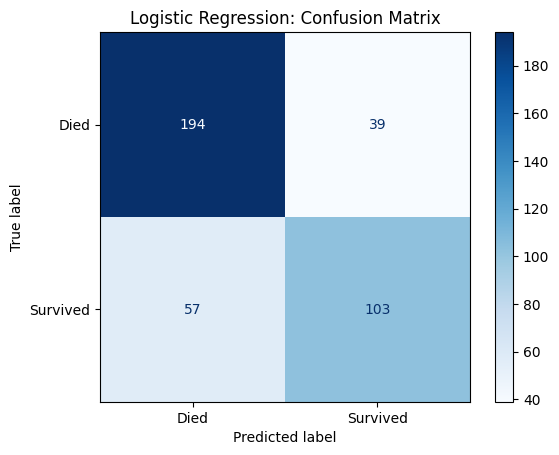

In [21]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

# fitted pipeline preprocesses the test data before making predictions
y_pred = model.predict(X_test)

print(f"Test accuracy: {accuracy_score(y_test, y_pred):.3f}")

# Calculate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display the confusion matrix
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Died", "Survived"],
).plot(cmap="Blues")

plt.title("Logistic Regression: Confusion Matrix")
plt.show()